# Comparing two sets of grids

Are synthetic grids like the real ones? A validation answers this by comparing the pylovo grids of an area with the
grids of the distribution system operator (DSO) that supplies the same buildings. DSO grid data are confidential, so
this notebook compares two pylovo versions of the same area instead. The **reference** takes the part of the DSO's
grids, the **candidate** that of the pylovo grids under test. Any of the versions could just as well be a real DSO
dataset of the same area: only the loading step changes (section 9).

| Role | Version in the example data | In a validation |
| --- | --- | --- |
| reference | `1`: the default run | the DSO's grids of the area |
| candidate | `tut-cabin`: houses connected through cable cabinets instead of tee joints | the pylovo grids under test |
| further candidates | `tut-osm`, `tut-reach`, `tut-large` (see `05_versions.ipynb`) | other settings or versions |

The candidate differs from the reference in one setting only, so the example also tests the method. Cable cabinets
keep the stations and change the cabling: the comparison should find the same stations and more cable to the houses.

Real and synthetic grids rarely share their boundaries, so the comparison does not pair grids. It compares the
distributions over the grids, one value per grid and metric, and totals over the whole area.

**Needs:** the `notebooks` extra (`uv sync --extra notebooks`). With a database in your `.env` the notebook reads the
grids from it, otherwise from the example data that ship with pylovo (`data/examples`, where the variants hold
postcode area 85256 only).

In [1]:
plz = 85256                                                # one area: both datasets supply the same buildings
reference = "1"                                            # stands in for the DSO's grids
candidate = "tut-cabin"                                    # the grids under test
candidates = ["tut-osm", "tut-reach", "tut-cabin", "tut-large"]   # section 8: several versions against the reference
min_buildings = 5                                          # smaller grids leave both datasets

In [2]:
import matplotlib.pyplot as plt

from pylovo.analysis import comparison
from pylovo.examples import TutorialData
from pylovo.plotting import comparison as comparison_plots
from pylovo.plotting import lv_grid, style

style.apply_style(dpi=150)
versions = list(dict.fromkeys([reference, candidate, *candidates]))
data = {version: TutorialData(plz, version) for version in versions}
for tutorial_data in data.values():
    print(tutorial_data)
colors = comparison_plots.group_colors(versions, reference)

TutorialData(plz=85256, version 1, from the example data: no database configured)
TutorialData(plz=85256, version tut-cabin, from the example data: no database configured)
TutorialData(plz=85256, version tut-osm, from the example data: no database configured)
TutorialData(plz=85256, version tut-reach, from the example data: no database configured)
TutorialData(plz=85256, version tut-large, from the example data: no database configured)


## 1 One area, two datasets

Both datasets supply the same buildings, each with its own grids (one colour per grid). This is what the comparison
needs: with a DSO dataset, keep only the buildings that both datasets supply.

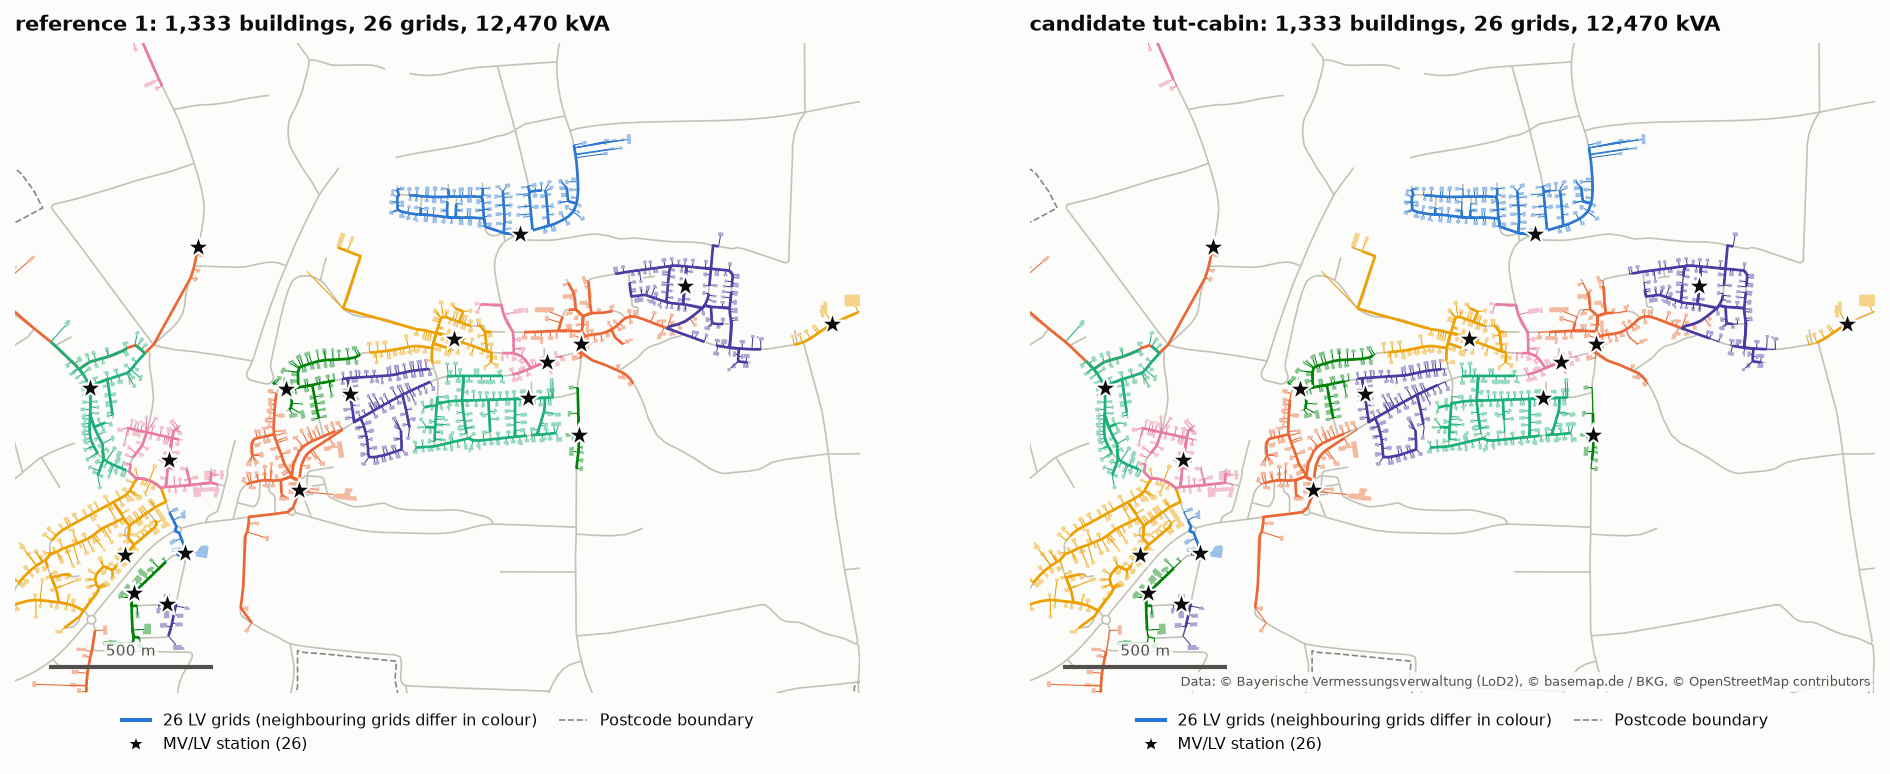

In [3]:
bounds = lv_grid.core_bounds(data[reference].layers)
fig, axes = plt.subplots(1, 2, figsize=(16, 6.4))
for ax, version, role in zip(axes, [reference, candidate], ["reference", "candidate"]):
    grids = data[version].grids
    buildings = data[version].layers["buildings"]
    lv_grid.plot_lv_overview(data[version].layers, extent=bounds, ax=ax, labels=False,
                             title=f"{role} {version}: {len(buildings):,} buildings, {len(grids)} grids, "
                                   f"{int(grids['transformer_rated_power'].sum()):,} kVA",
                             attribution="" if version == reference else None)

## 2 Eight metrics per grid

Each grid is described by eight metrics in a matrix: the columns ask how large, branched and long the network is
(network topology) and how much capacity and resistance it has (electrical sizing); the rows look at the station, the
feeders, the building and the route to the farthest house.

In [4]:
comparison.metric_catalogue()

metric  \
category          row                                               
Network topology  Station                      Buildings per grid   
                  Feeders                      Feeder branch ends   
                  Per building          Cable length per building   
                  Route                             Longest route   
Electrical sizing Station                        Transformer size   
                  Feeders                         Feeder capacity   
                  Per building  Transformer capacity per building   
                  Route                  Highest route resistance   

                                        unit  \
category          row                          
Network topology  Station          buildings   
                  Feeders              count   
                  Per building             m   
                  Route                    m   
Electrical sizing Station                kVA   
                  Feeders       A per feeder   
                  Per building           kVA   
                  Route                   mΩ   

                                                                          meaning  
category          row                                                              
Network topology  Station                       Size of a transformer supply area  
                  Feeders       Ends of the feeder network without house conne...  
                  Per building  Installed cable to the houses, parallel cables...  
                  Route         Cable distance from the station to the farthes...  
Electrical sizing Station                           Rated capacity of the station  
                  Feeders       Current rating of a cable leaving the station;...  
                  Per building          Station capacity divided by its buildings  
                  Route         Cable resistance from the station to the worst...

How the metrics are measured, the same way for every dataset:

- The network of a grid is rebuilt from its cable geometries and followed from the station. Every cable end without a
  further cable is a house connection.
- **Feeders** start where the station ends: links of up to 2 m from the station busbar belong to the station.
- **Feeder branch ends** count the ends of the network after removing every cable that supplies only one building. A
  star of house cables at a cable cabinet and a row of tee joints therefore count alike.
- **Feeder capacity** rates each cable as the aluminium cable (NAYY) with the same resistance, so a DSO's copper
  cables count like the aluminium cables they equal. Parallel cables add up.
- **Routes** run to the house, including the house connection cable.

Grids with fewer than `min_buildings` buildings leave both datasets: DSO data often hold no such grids or only
fragments of them, and a few tiny grids would dominate the metrics per building.

In [5]:
all_grids, metrics = {}, {}
for version, tutorial_data in data.items():
    layers = tutorial_data.layers
    table = comparison.grid_metrics(layers["lines"], layers["grids"], comparison.cable_resistances(tutorial_data.parameters))
    small = table["building_count"] < min_buildings
    print(f"{version}: {len(table)} grids, {small.sum()} with fewer than {min_buildings} buildings left out")
    all_grids[version], metrics[version] = table, table[~small].reset_index(drop=True)
pair = {reference: metrics[reference], candidate: metrics[candidate]}
metrics[candidate].head().round(3)

1: 26 grids, 1 with fewer than 5 buildings left out
tut-cabin: 26 grids, 1 with fewer than 5 buildings left out


tut-osm: 23 grids, 1 with fewer than 5 buildings left out
tut-reach: 24 grids, 0 with fewer than 5 buildings left out


tut-large: 21 grids, 2 with fewer than 5 buildings left out


,kcid,bcid,building_count,feeder_branching_endpoints,cable_length_per_building_m,max_supply_path_m,transformer_bank_capacity_kva,feeder_capacity_a,transformer_capacity_per_building_kva,max_series_resistance_ohm,feeders,cable_km,route_km,feeder_head_capacity_a,buildings_behind_feeders
0,1,1,7,2,96.966,381.059,400.0,270.000,57.143,0.101,2,0.679,0.679,540.0,4
1,1,2,5,0,268.517,1102.710,400.0,NaN,80.000,0.263,0,1.343,1.343,0.0,0
2,1,3,157,11,53.357,598.540,630.0,469.667,4.013,0.127,3,8.377,8.298,1409.0,144
3,1,4,81,8,48.705,359.512,400.0,308.750,4.938,0.088,4,3.945,3.945,1235.0,77
4,1,5,10,1,91.979,255.037,630.0,270.000,63.000,0.083,1,0.920,0.920,270.0,4


## 3 Scorecard

Per metric the grid medians of both datasets, and Δ: the typical difference between a candidate grid and a reference
grid (the Hodges–Lehmann shift, the median of all such differences) in % of the reference median. Δ shows "≈" when
the two distributions do not differ beyond sampling noise, and "differs" when they do but the typical difference is
zero, e.g. for standard transformer sizes.

In [6]:
scores = comparison.compare(metrics[reference], metrics[candidate])
comparison.scorecard(scores, names=(reference, candidate))

,unit,1,tut-cabin,Δ
metric,,,,
Grids,count,25,25,+0%
Buildings per grid,buildings,57,57,≈
Feeder branch ends,count,4,4,≈
Cable length per building,m,40,55,≈
Longest route,m,398,422,≈
Transformer size,kVA,400,400,≈
Feeder capacity,A per feeder,299,283,≈
Transformer capacity per building,kVA,11.1,11.1,≈
Highest route resistance,mΩ,85,103,≈


The numbers behind the scorecard:

- **W1**, the Wasserstein-1 distance: the area between the two distribution functions (section 5), in the unit of the
  metric. It is zero only for identical distributions and grows with every shift or change of shape.
- **W̃1**: W1 divided by the interquartile range of the reference, so that the metrics can be compared with each
  other.
- **floor (p90)**: the W̃1 that even a perfect generator reaches, the distance between two resamples of the reference
  alone (90th percentile). With few grids it is large, and a W̃1 below it says little.
- **p**: the share of random relabellings of the pooled grids whose W1 is at least the observed one (a permutation
  test). Below 0.05 the candidate differs: "lower" or "higher" by the sign of Δ.

In [7]:
comparison.score_details(scores)

,grids,W1,unit,W̃1,floor (p90),p,verdict
metric,,,,,,,
Buildings per grid,25 | 25,0.00,buildings,0.000,0.312,1.000,same
Feeder branch ends,25 | 25,0.16,count,0.027,0.333,1.000,same
Cable length per building,25 | 25,14.97,m,0.407,0.664,0.465,same
Longest route,25 | 25,8.83,m,0.031,0.398,1.000,same
Transformer size,25 | 25,0.00,kVA,0.000,0.240,1.000,same
Feeder capacity,25 | 24,8.06,A per feeder,0.133,1.661,0.972,same
Transformer capacity per building,25 | 25,0.00,kVA,0.000,0.270,1.000,same
Highest route resistance,25 | 25,13.94,mΩ,0.395,0.766,0.633,same


The station metrics are identical (W1 = 0): cable cabinets keep the stations and their grids. The cable length per
building and the route resistance rise at the median, and still Δ shows "≈": the grids of one dataset differ so much
among themselves that 25 grids cannot tell a shift of this size from sampling noise (W̃1 stays below its floor). "≈"
means "not distinguishable with these grids", not "equal". The totals and the cable choice below show the change.

## 4 Totals over the area

Both datasets supply the same buildings, so totals over the area compare directly and do not depend on where the grid
boundaries lie: each total sums over all grids, including the small ones, before dividing. They have no test, as each
is one number per dataset.

In [8]:
comparison.area_totals({reference: all_grids[reference], candidate: all_grids[candidate]}).round(2)

,1,tut-cabin,ratio
grids,26.00,26.00,1.00
buildings,1333.00,1333.00,1.00
transformer capacity (MVA),12.47,12.47,1.00
"cable (km, parallel cables counted)",53.32,75.59,1.42
feeder branch ends per 100 buildings,9.75,9.83,1.01
cable length per building (m),40.00,56.70,1.42
"route length per building (m, parallel cables once)",39.14,55.93,1.43
transformer capacity per building (kVA),9.35,9.35,1.00
feeder capacity per building behind it (A),17.75,18.45,1.04


The totals show what the scorecard could not separate from noise: with the same stations and grids, the candidate
installs about 40 % more cable for the same buildings. A total sums the small differences of all grids, while the
test weighs each shift against the spread between grids.

## 5 Distributions

### Box plots

The eight metrics in their matrix. The box holds the middle half of the grids, the line is the median, and the
whiskers reach the last grid within 1.5 box lengths (`show_outliers=True` draws the grids beyond). A box drawn as a
flat line means that at least half of the grids share one value, such as a standard transformer size.

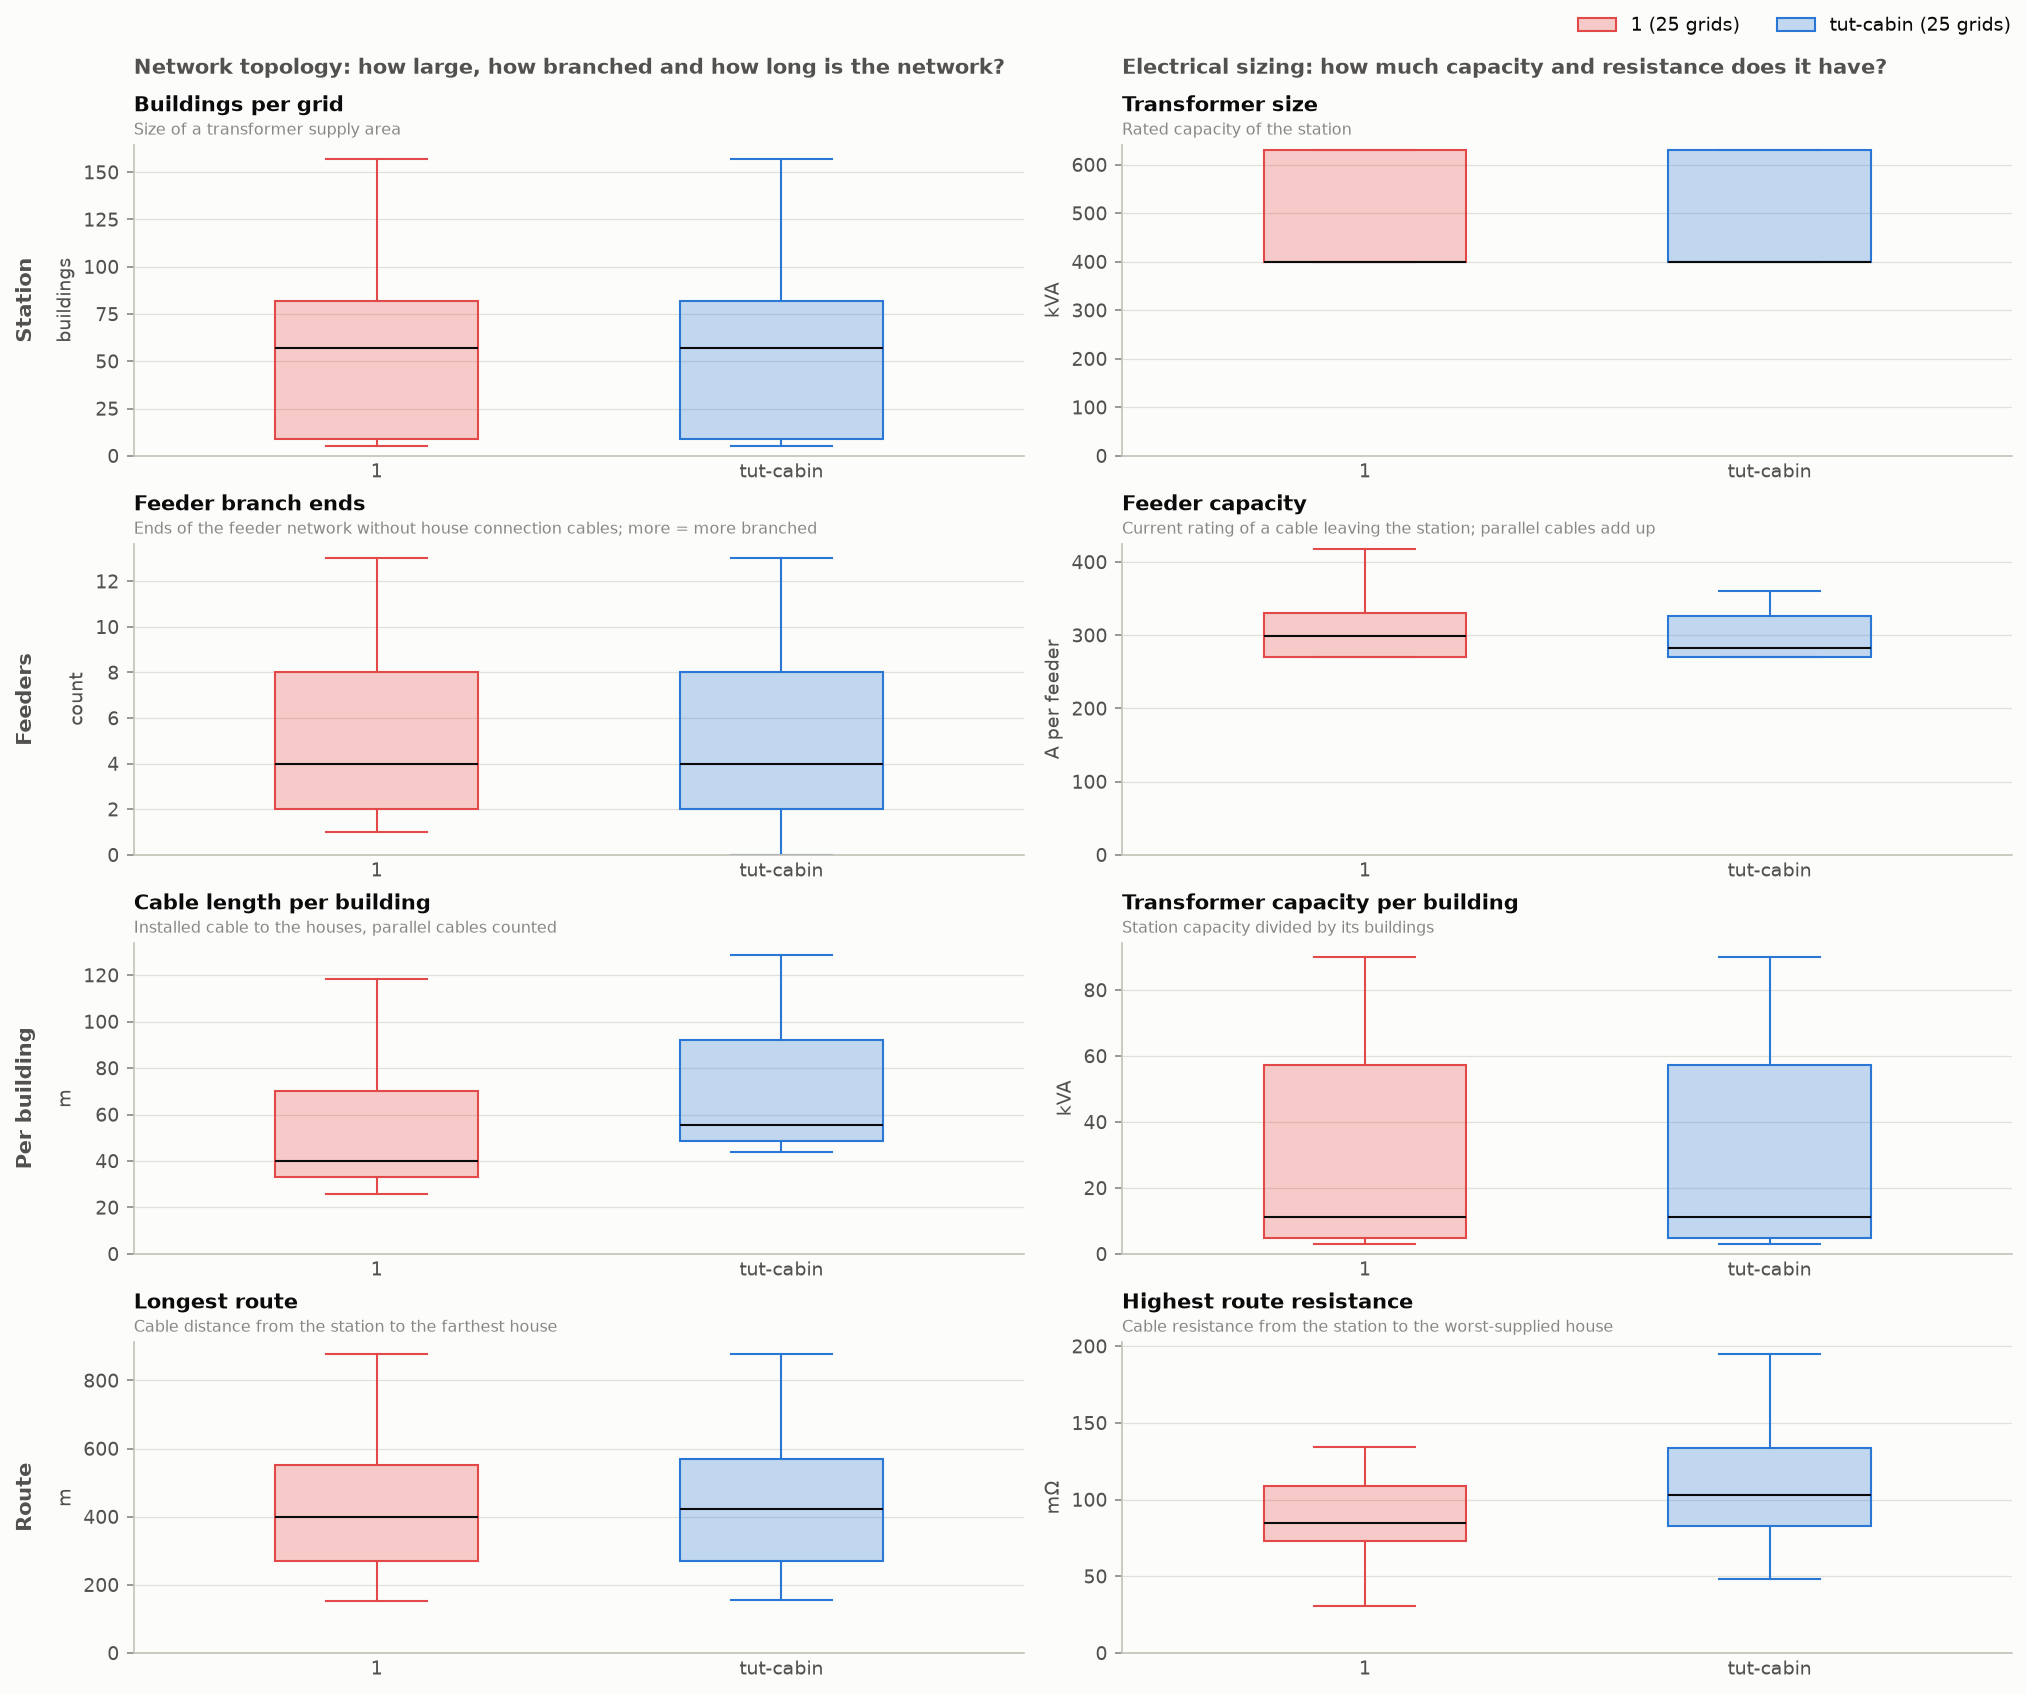

In [9]:
comparison_plots.plot_boxplots(pair, colors);

### Distribution functions and Wasserstein-1 distance

Each panel shows the box plots above the empirical distribution functions, the share of grids up to each value. The
medians lie where the curves cross 0.5. The shaded area between the curves is W1 within the displayed range; its
colour gives W̃1, grey when the difference is within sampling noise. A shift moves a curve sideways, a wider spread
makes it flatter. The lower right gives W̃1 and, in brackets, W1 in the unit of the metric. Where both datasets have
the same values, as for the station metrics here, the candidate's curve hides the reference's.

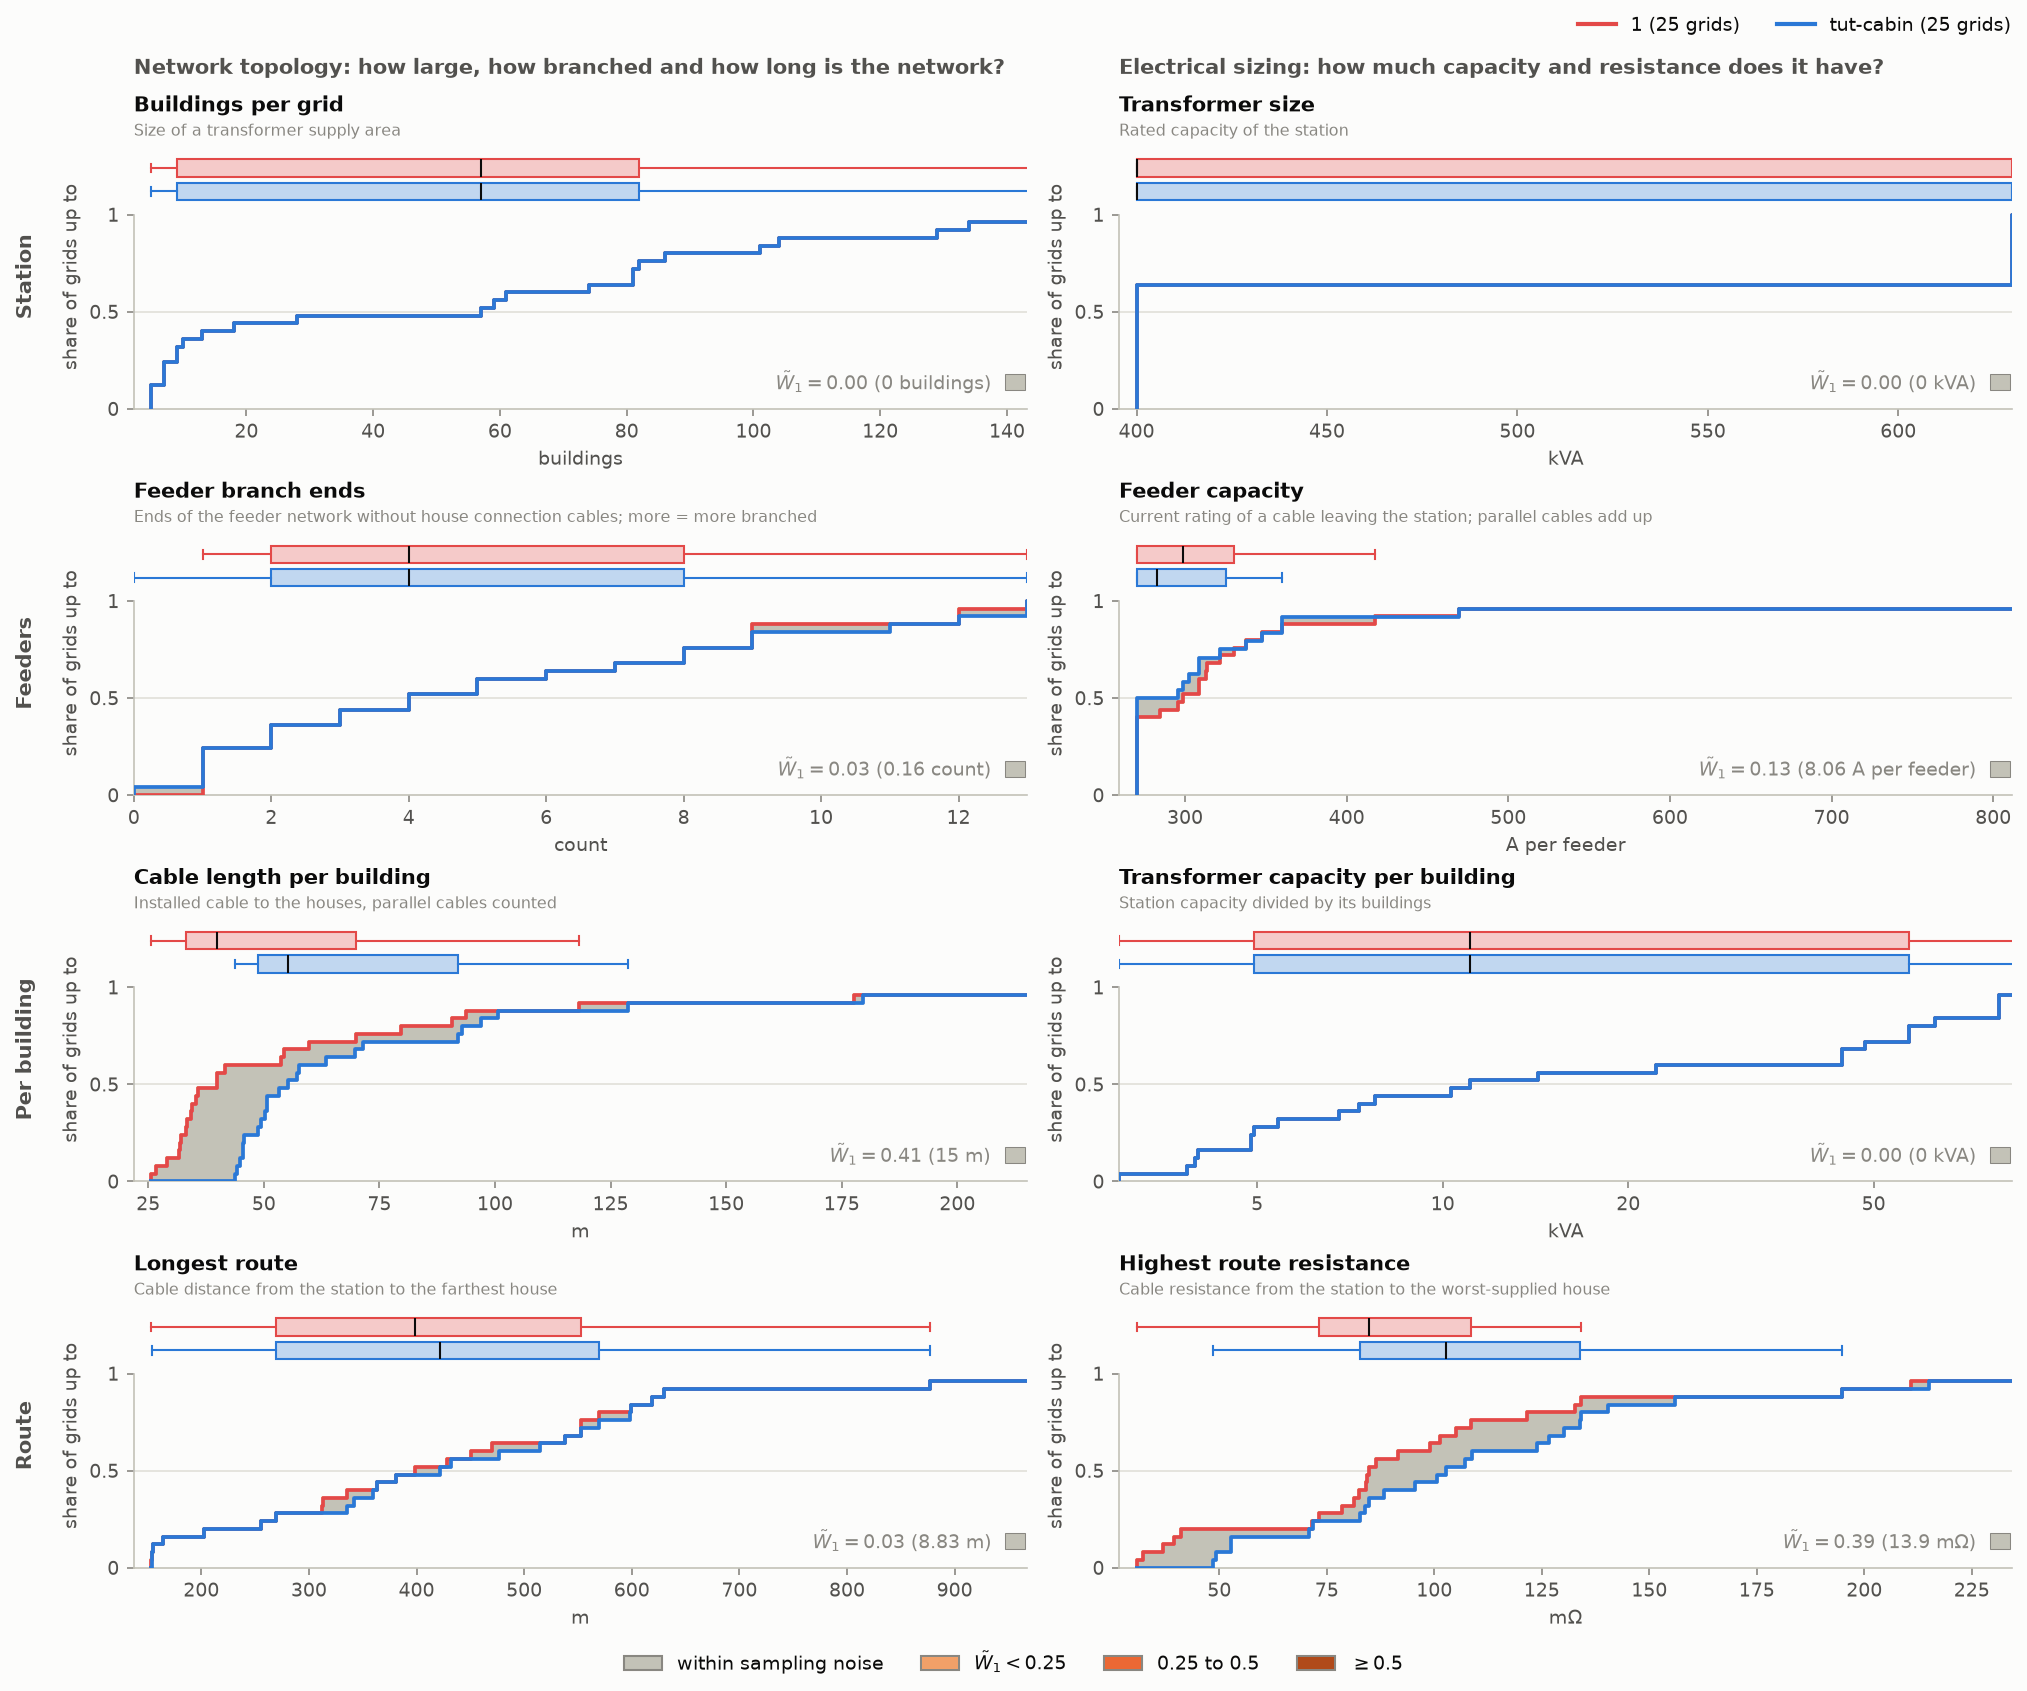

In [10]:
comparison_plots.plot_distributions(pair, colors, scores);

### Histograms

The same distributions as histograms with shared bins, each dataset normalized to its own share of grids. The curves
are smoothed guides (kernel density estimates), not more data. With 20 to 30 grids per dataset the bars depend on
where the bins start, so the distribution functions above are the safer read.

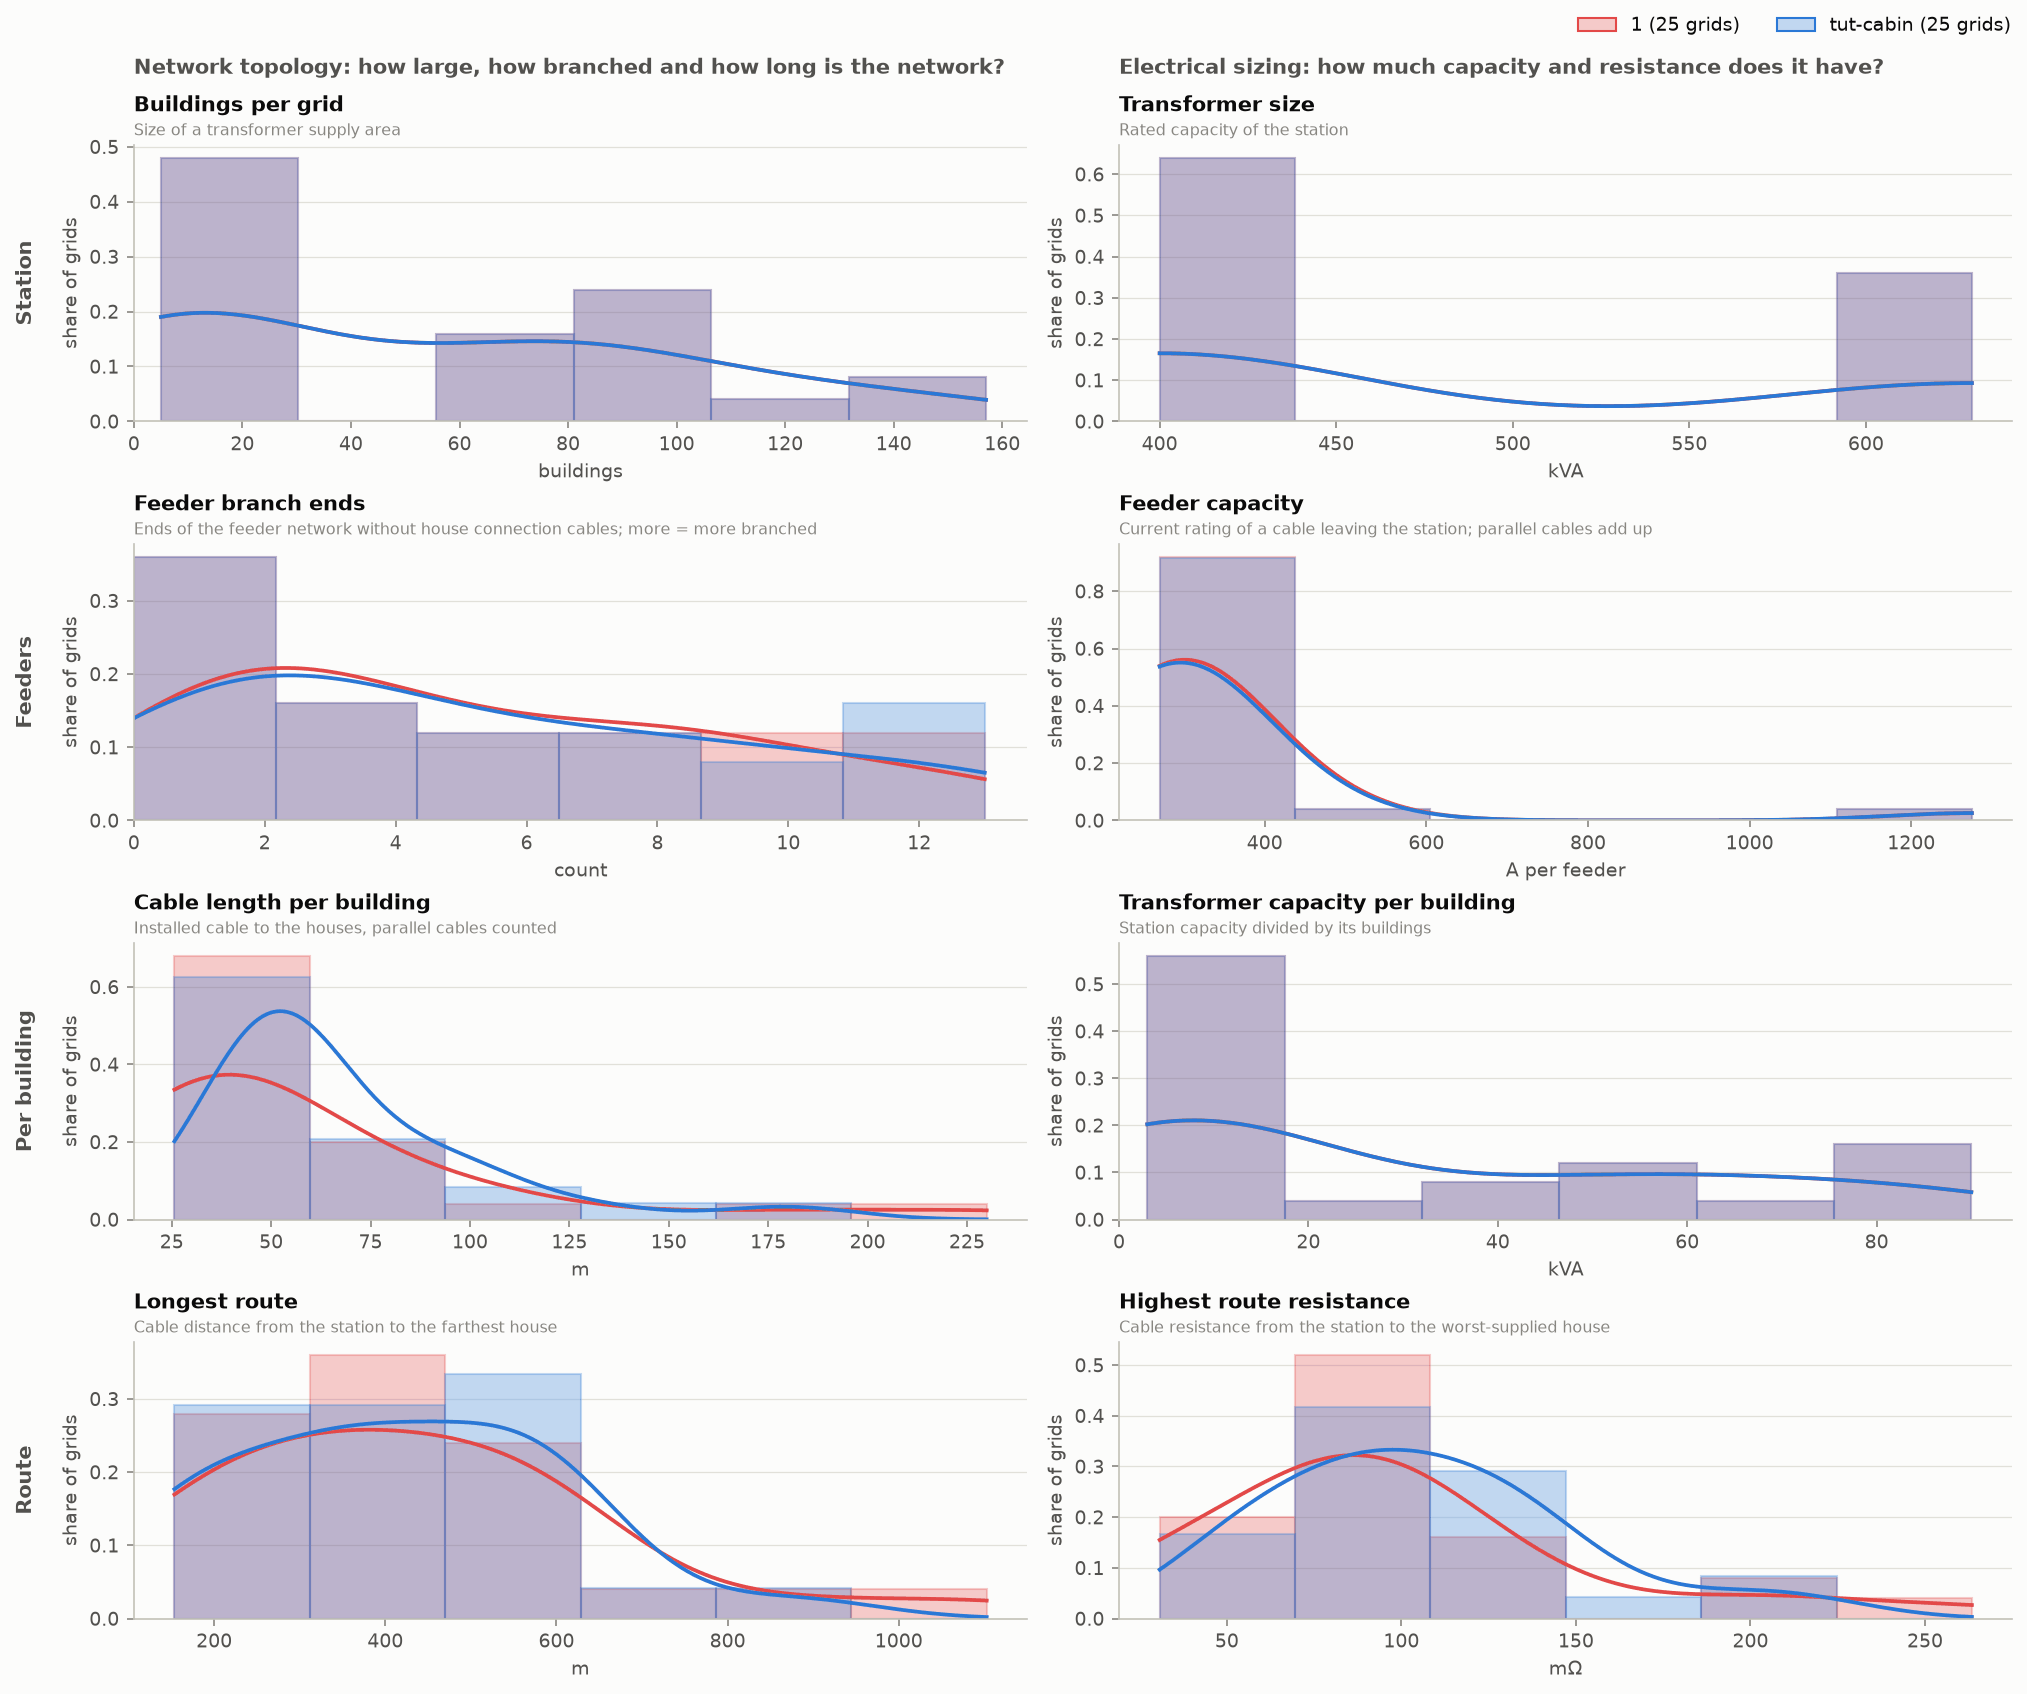

In [11]:
comparison_plots.plot_histograms(pair, colors, bins=6);

## 6 How the metrics go together

Two datasets can agree metric by metric and still differ in how the metrics go together, e.g. when larger grids have
longer routes in one dataset but not in the other. The rank correlations (Spearman) between the metrics over the
grids of each dataset show this, and their difference. With about 25 grids per dataset, a correlation is uncertain
by about ±0.4 and a difference of two by about ±0.6, so only large differences count.

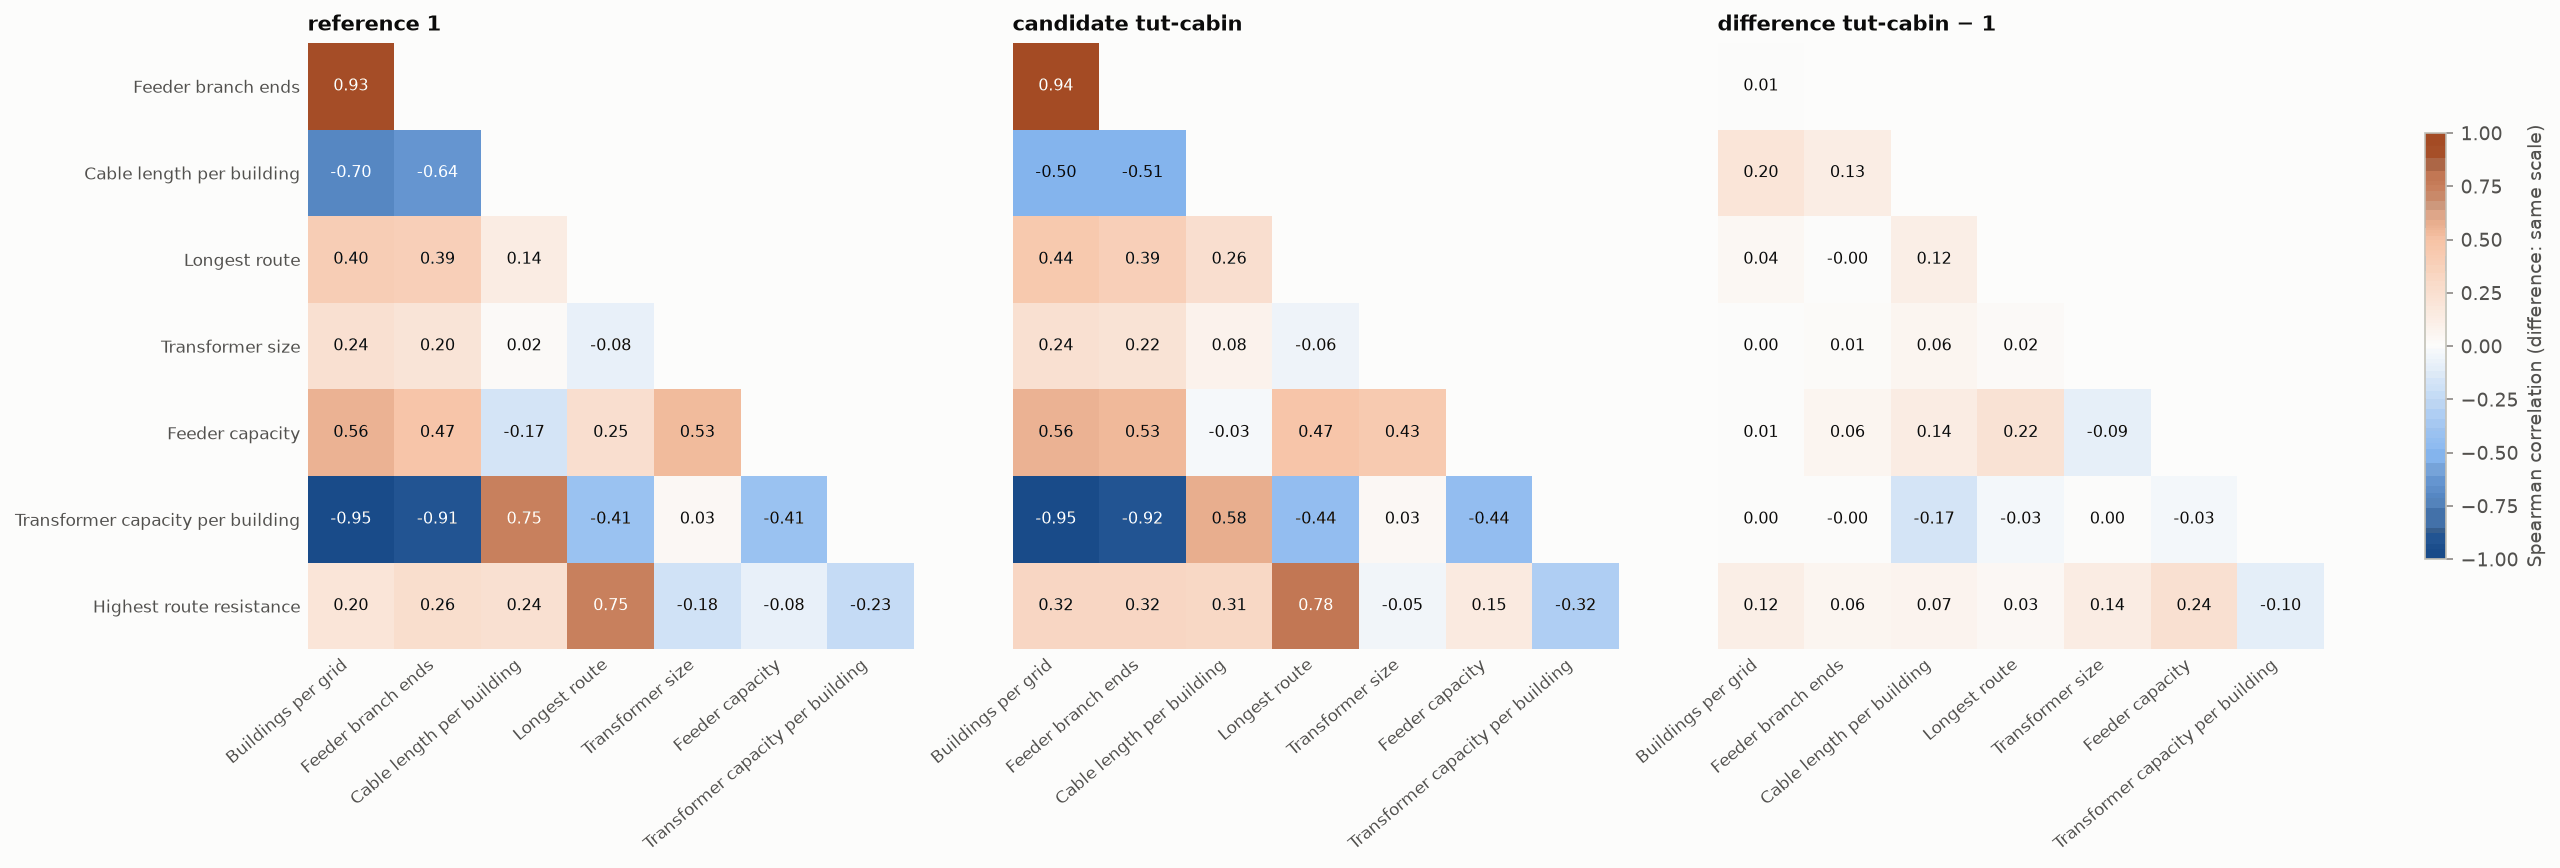

In [12]:
comparison_plots.plot_correlations(pair);

## 7 Cable choice

Which cables carry the grids? The share of installed length per cable size, for feeders and house services
separately, over all grids of the area. Cables are classed by the aluminium cable with the same resistance, so a
DSO's copper cables or other types fall into the same classes. The table gives the installed length and the share of
feeder cable laid in parallel, where one cable was not enough.

,1,tut-cabin
feeders (km),31.8,28.8
house services (km),21.5,46.8
feeder cable in parallel (%),6.5,6.4


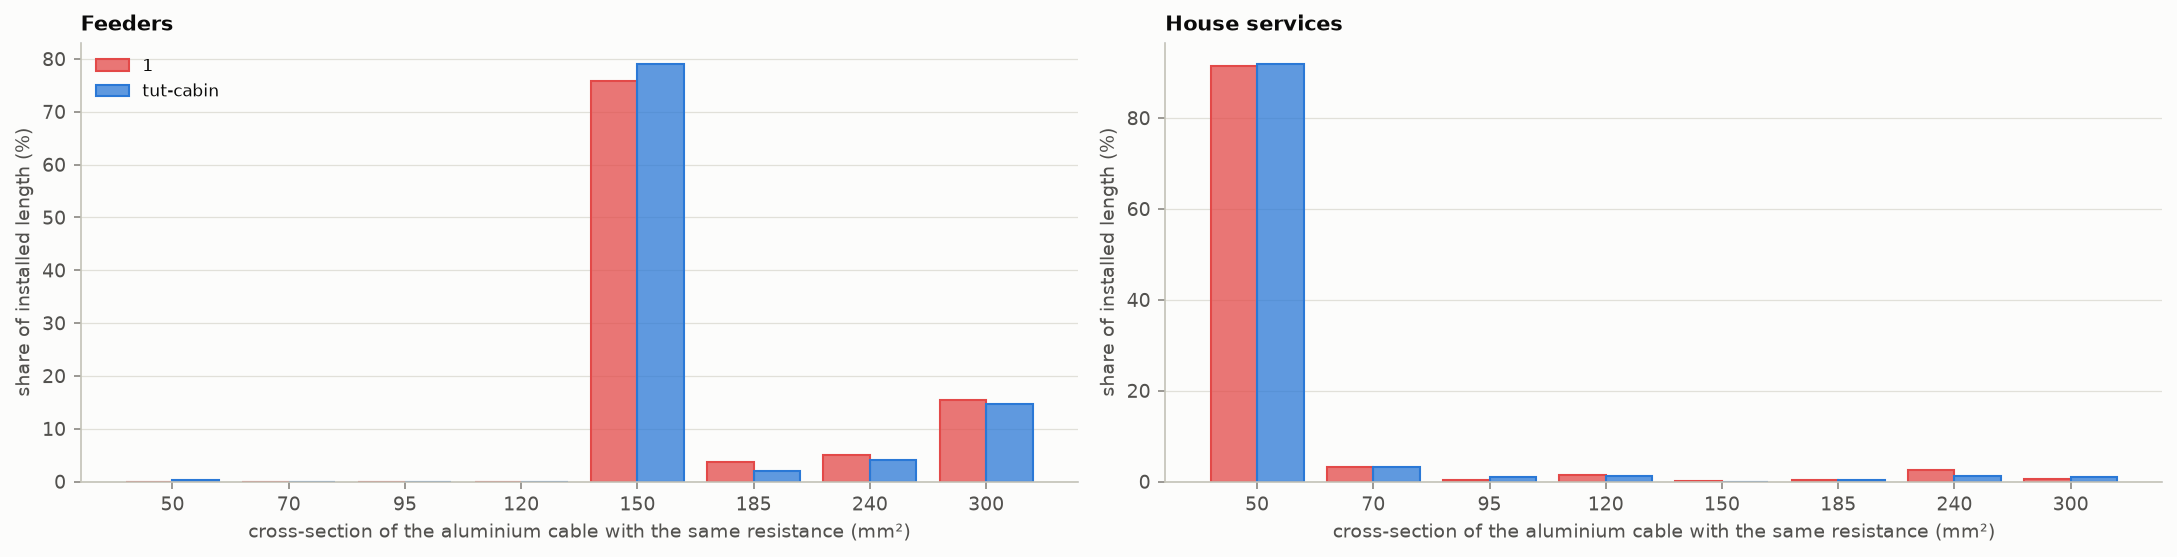

In [13]:
cables = {version: comparison.cable_table(data[version].layers["lines"], comparison.cable_resistances(data[version].parameters))
          for version in pair}
display(comparison.cable_summary(cables))
comparison_plots.plot_cable_shares(cables, colors);

The extra cable is house connection cable: with cabinets, the house services more than double in length, while the
feeders get a little shorter, as part of each feeder route is now covered by house cables. The cable sizes hardly
change.

## 8 Several versions against one reference

Which setting brings pylovo closest to the reference? Each version of `candidates` is scored against the reference as
in section 3. Each cell gives W̃1, grey within sampling noise and orange the farther the distributions lie apart.
With eight metrics and several versions, a single "differs" can occur by chance: at p < 0.05, about one test in
twenty.

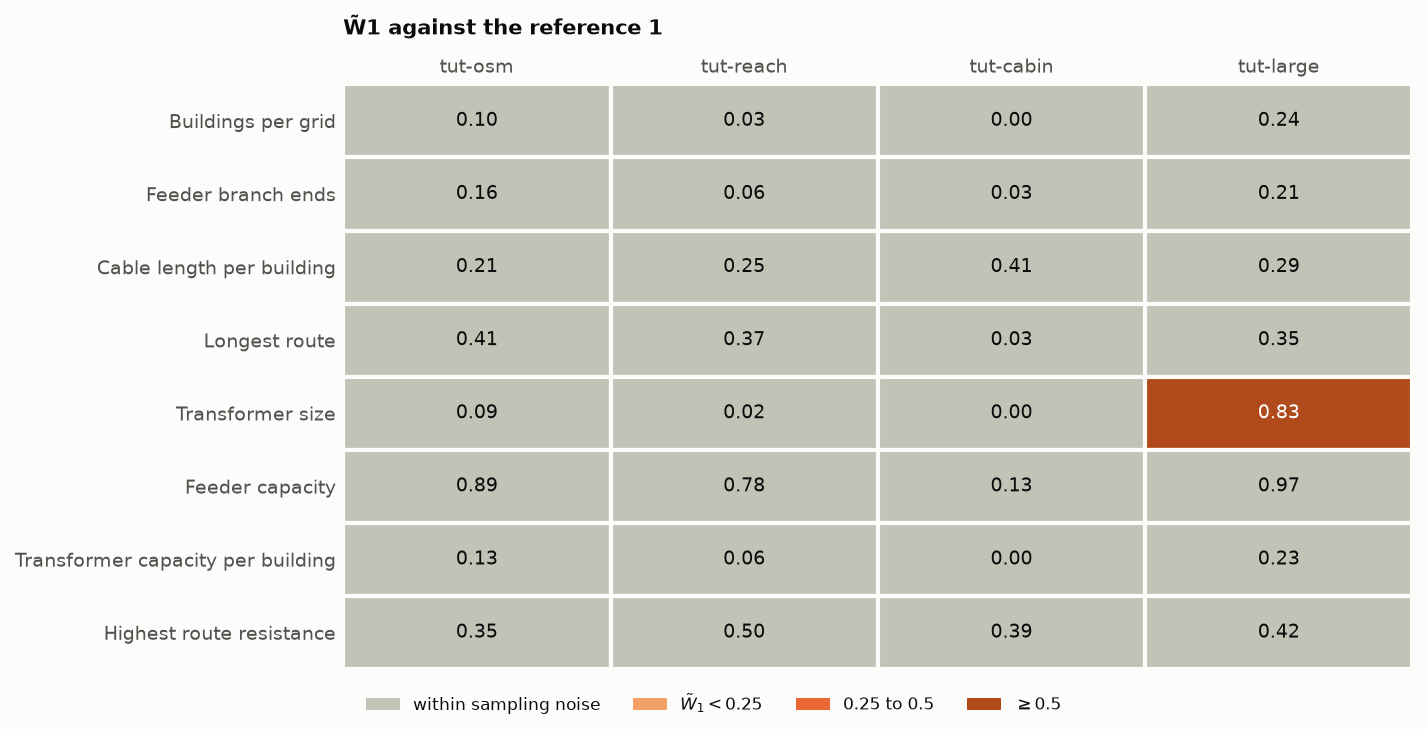

In [14]:
by_version = {version: comparison.compare(metrics[reference], metrics[version]) for version in candidates}
comparison_plots.plot_score_matrix(by_version, title=f"W̃1 against the reference {reference}");

In [15]:
comparison.ranking(by_version)

,metrics within sampling noise,median W̃1,most different metric,its p
version,,,,
tut-cabin,8,0.029,Cable length per building,0.465
tut-reach,8,0.157,Longest route,0.421
tut-osm,8,0.186,Longest route,0.168
tut-large,7,0.324,Transformer size,0.001


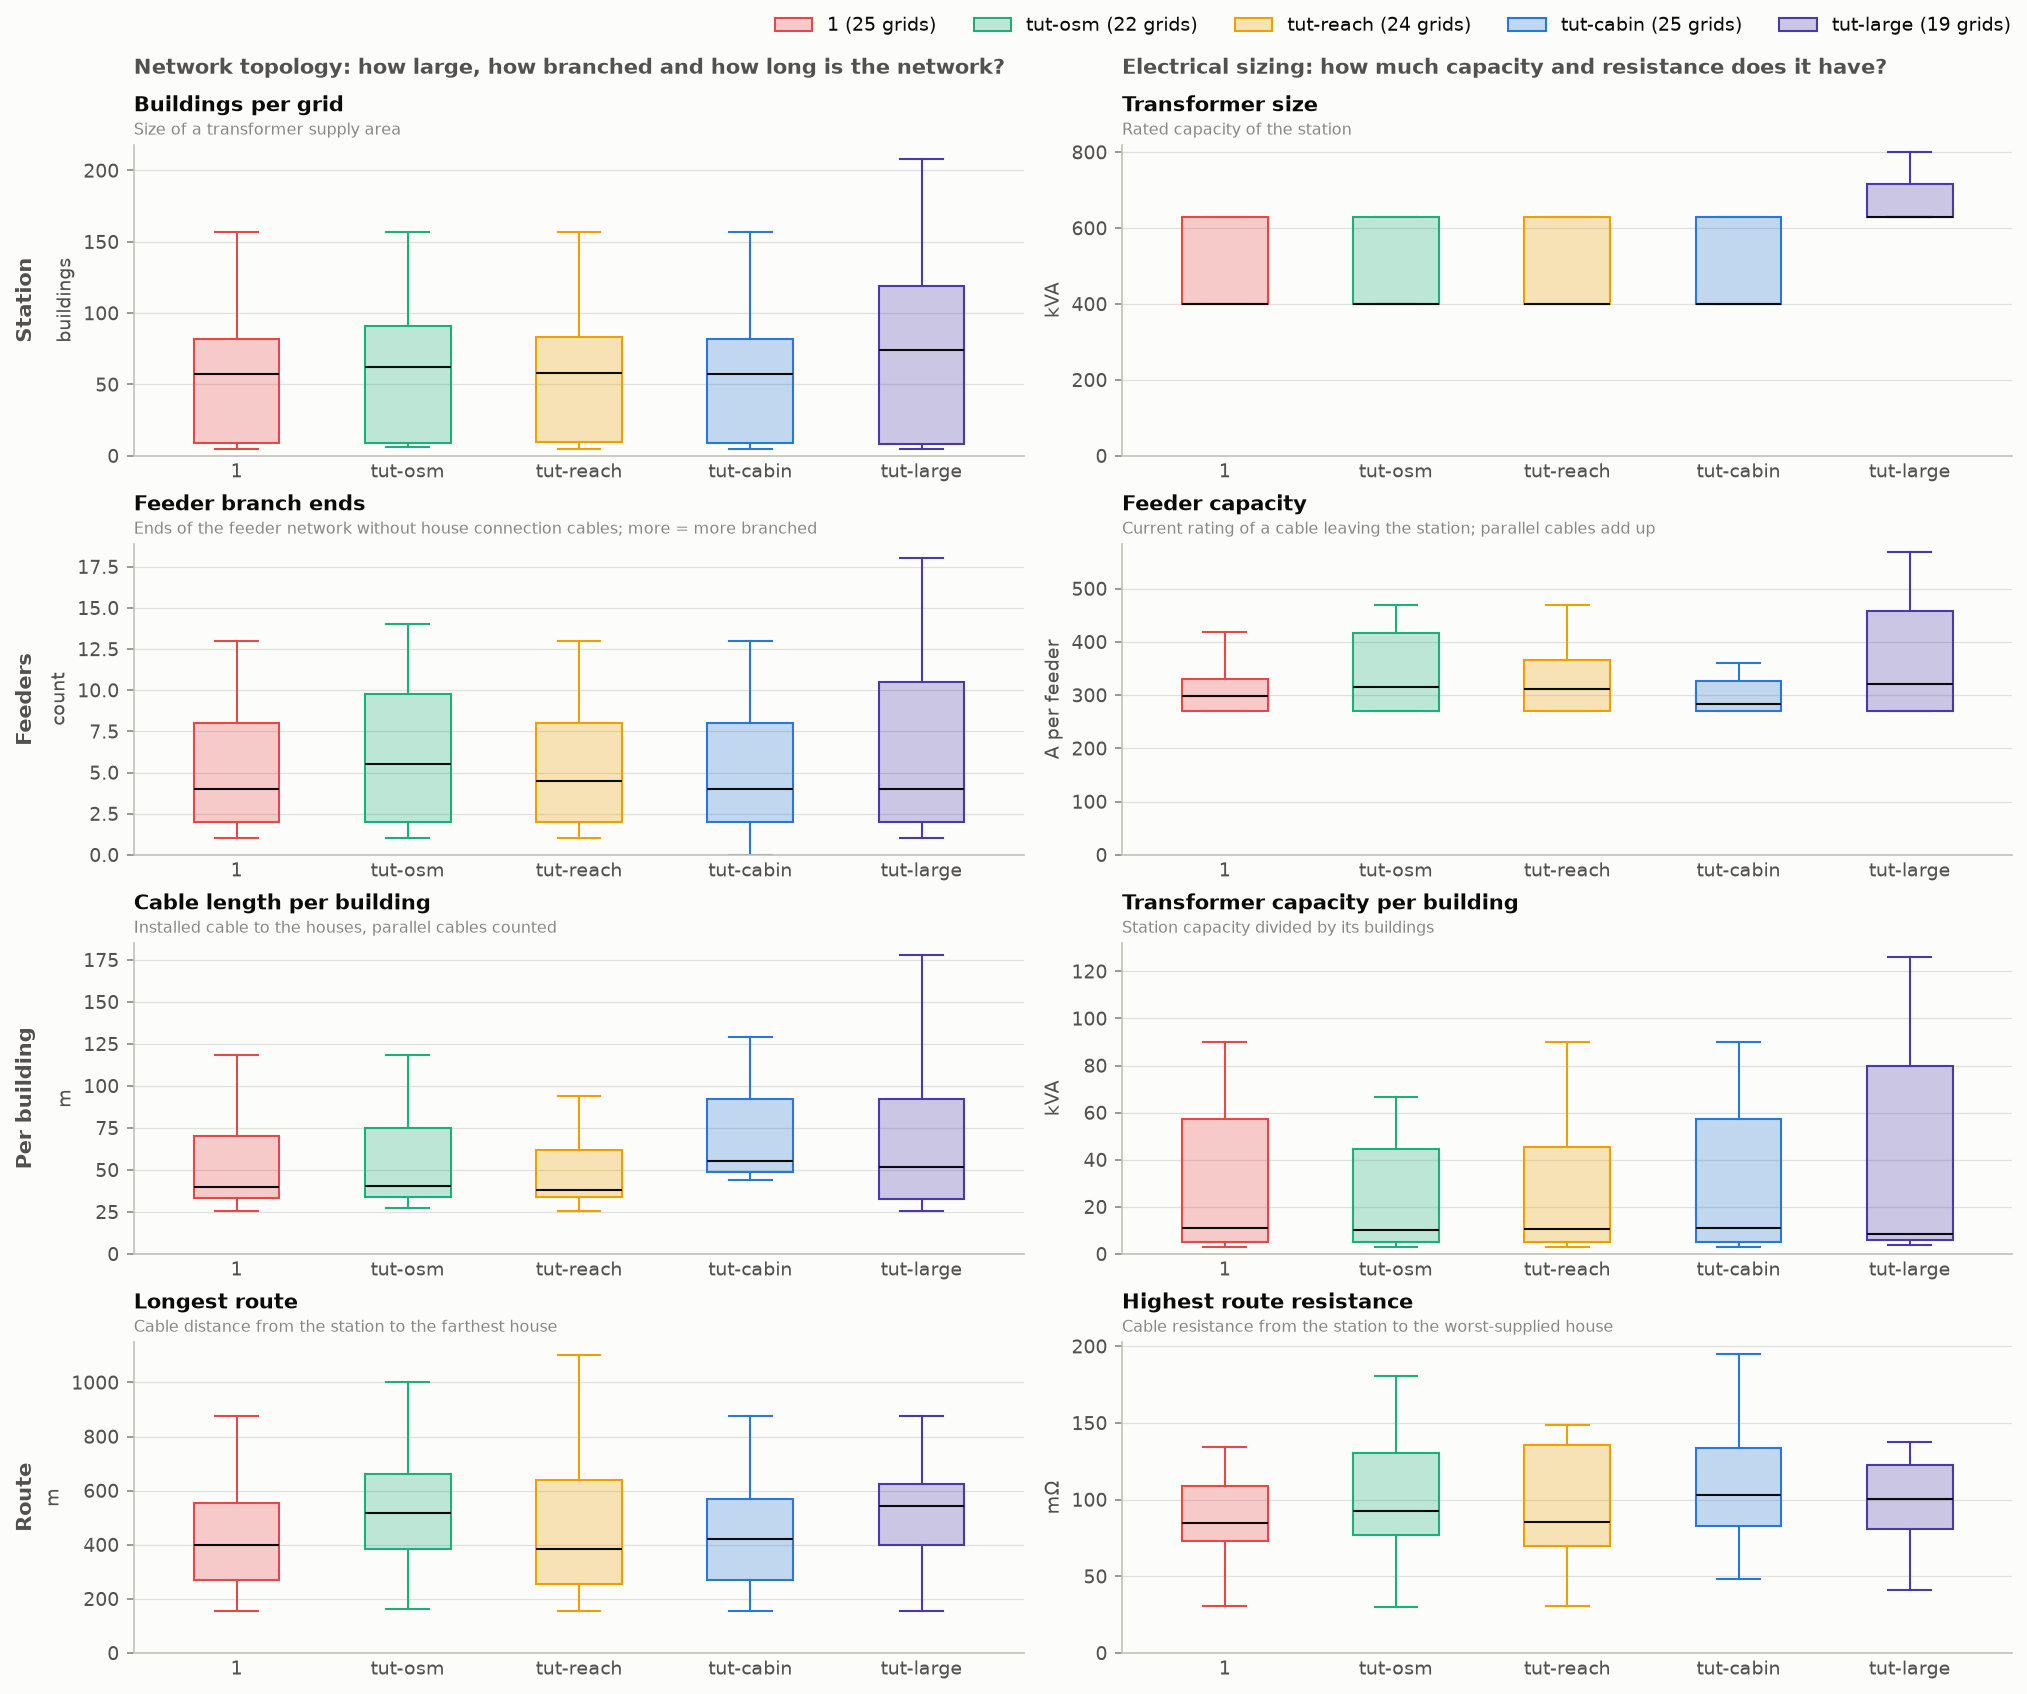

In [16]:
comparison_plots.plot_boxplots({version: metrics[version] for version in [reference, *candidates]}, colors);

In [17]:
comparison.area_totals({version: all_grids[version] for version in [reference, *candidates]}).round(2)

,1,tut-osm,tut-reach,tut-cabin,tut-large
grids,26.00,23.00,24.00,26.00,21.00
buildings,1333.00,1333.00,1333.00,1333.00,1333.00
transformer capacity (MVA),12.47,11.50,11.67,12.47,14.08
"cable (km, parallel cables counted)",53.32,55.40,54.95,75.59,53.68
feeder branch ends per 100 buildings,9.75,10.20,9.68,9.83,9.23
cable length per building (m),40.00,41.56,41.22,56.70,40.27
"route length per building (m, parallel cables once)",39.14,40.40,40.68,55.93,39.19
transformer capacity per building (kVA),9.35,8.63,8.75,9.35,10.56
feeder capacity per building behind it (A),17.75,17.64,17.95,18.45,15.19


Only the larger stations of `tut-large` differ beyond sampling noise: a larger rating step moves the station sizes
of most grids at once. The other settings shift the grids by less than the grids of one dataset differ among
themselves, so about 25 grids cannot separate them from noise, and their effect shows in the totals. A DSO dataset of
one municipality is just as small: pool several areas for a stronger test.

## 9 Your own reference data

To compare pylovo with real grids, replace the reference by the DSO's data:

1. **The same buildings.** Generate pylovo grids for the area that the DSO's grids cover
   (`uv run pylovo-generate --plz ...`) and keep, on both sides, only the grids that supply buildings of both
   datasets.
2. **Cables and stations.** `comparison.grid_metrics` needs one row per cable section (the grid as `kcid` and `bcid`,
   `std_type`, `length_km`, `parallel` and the line geometry from one end to the other), one row per station (`kcid`,
   `bcid`, `transformer_rated_power` in kVA and a point) and the resistance per cable type. An export from the DSO's
   GIS usually holds exactly this. Remove open cable ends, such as reserve cables, first: every cable end counts as a
   house.
3. **Run the notebook** with the DSO's metrics as the reference:

```python
import geopandas as gpd

dso_lines = gpd.read_file("dso_grids.gpkg", layer="cables")       # kcid, bcid, std_type, length_km, parallel
dso_stations = gpd.read_file("dso_grids.gpkg", layer="stations")  # kcid, bcid, transformer_rated_power
resistance = {"NAYY 4x150": 0.208, "NYY 4x95": 0.193}              # ohm/km per cable type
all_grids["DSO"] = comparison.grid_metrics(dso_lines, dso_stations, resistance)
metrics["DSO"] = all_grids["DSO"][all_grids["DSO"]["building_count"] >= min_buildings]
reference = "DSO"
```

DSO data are usually confidential: clear the outputs before you share or commit the notebook.